# 01 - Exploratory Data Analysis

Run `python -m src.pipeline` once before this notebook. It creates the cleaned transactions and the customer feature table that are loaded here.

The notebook ends with a written list of **hypotheses** that the modeling stage will test.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.features.analysis import target_correlations, vif_table
from src.features.build_features import TARGET_COLUMNS, feature_columns
from src.utils.config import load_config, resolve_path

cfg = load_config()
CATEGORIES = cfg["features"]["categories"]
FEATURES = feature_columns(CATEGORIES)
sns.set_theme(style="whitegrid")

## 1. Cleaned transactions: overview

In [2]:
tx = pd.read_csv(resolve_path(cfg["paths"]["interim_transactions"]), parse_dates=["invoice_date"], low_memory=False)
print(tx.shape)
tx.head()

(1026947, 15)


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,is_cancellation,is_return,has_customer,is_non_product,is_bulk_quantity,is_high_price,line_total
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,True,False,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,True,False,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,True,False,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,True,False,True,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,True,False,False,False,30.0


In [3]:
print(tx.dtypes)
print()
print("Missing values per column:")
print(tx.isna().sum())
print()
print(tx[["quantity", "price", "line_total"]].describe().round(2))

invoice                        str
stock_code                     str
description                    str
quantity                     int64
invoice_date        datetime64[us]
price                      float64
customer_id                float64
country                        str
is_cancellation               bool
is_return                     bool
has_customer                  bool
is_non_product                bool
is_bulk_quantity              bool
is_high_price                 bool
line_total                 float64
dtype: object

Missing values per column:
invoice                  0
stock_code               0
description              0
quantity                 0
invoice_date             0
price                    0
customer_id         229162
country                  0
is_cancellation          0
is_return                0
has_customer             0
is_non_product           0
is_bulk_quantity         0
is_high_price            0
line_total               0
dtype: int64

         quant

In [4]:
import json
report = json.loads(resolve_path(cfg["paths"]["pipeline_report"]).read_text())
pd.Series(report["cleaning"]).to_frame("value")

,value
rows_in,1067371.0
exact_duplicates_removed,34335.0
non_positive_price_removed,6019.0
data_entry_errors_removed,70.0
rows_out,1026947.0
rows_without_customer_id,229162.0
return_lines,19058.0
non_product_lines,5702.0
bulk_quantity_flagged,53054.0
high_price_flagged,66130.0


## 2. Revenue over time and by country (seasonality)

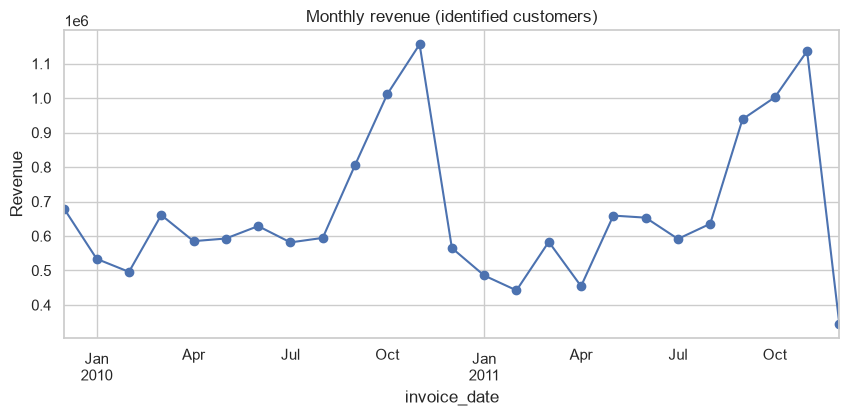

In [5]:
sales = tx[(tx["quantity"] > 0) & tx["has_customer"] & ~tx["is_non_product"]]
monthly = sales.set_index("invoice_date")["line_total"].resample("MS").sum()
ax = monthly.plot(marker="o", figsize=(10, 4), title="Monthly revenue (identified customers)")
ax.set_ylabel("Revenue")
plt.show()

In [6]:
by_country = sales.groupby("country").agg(revenue=("line_total", "sum"), customers=("customer_id", "nunique"))
by_country.sort_values("revenue", ascending=False).head(10)

,revenue,customers
country,,
United Kingdom,14043120.30,5334
EIRE,586626.08,3
Netherlands,549773.41,22
Germany,383289.00,107
France,309403.16,93
Australia,167800.01,15
Spain,97766.75,38
Switzerland,93400.94,22
Sweden,86045.14,19


## 3. Customer-level distributions (features table)

In [7]:
cust = pd.read_csv(resolve_path(cfg["paths"]["processed_features"]))
print(cust.shape, "| churn rate:", round(cust["churn_90d"].mean(), 3))
cust[FEATURES[:13] + TARGET_COLUMNS].describe().T.round(2)

(5256, 26) | churn rate: 0.565


,count,mean,std,min,25%,50%,75%,max
recency_days,5256.0,205.93,174.40,0.00,49.00,163.00,324.00,647.00
frequency,5256.0,5.71,11.21,1.00,1.00,3.00,6.00,284.00
monetary_total,5256.0,2588.78,12048.30,1.55,316.56,776.16,2061.54,456780.49
monetary_avg,5256.0,364.76,530.31,1.55,173.85,275.02,407.09,14844.77
clv_historical,5256.0,2516.89,11800.02,-1663.06,310.05,758.34,2002.20,454202.09
avg_basket_qty,5256.0,242.32,1336.08,1.00,88.00,149.00,254.00,87167.00
avg_basket_lines,5256.0,20.90,17.56,1.00,9.71,17.00,26.80,220.00
frequency_trend,5256.0,-0.08,0.18,-3.00,-0.06,-0.03,-0.02,1.00
gap_variance,5256.0,1983.40,4736.53,0.00,0.00,66.52,1831.27,97016.89
seasonal_concentration,5256.0,0.56,0.34,0.09,0.26,0.50,1.00,1.00


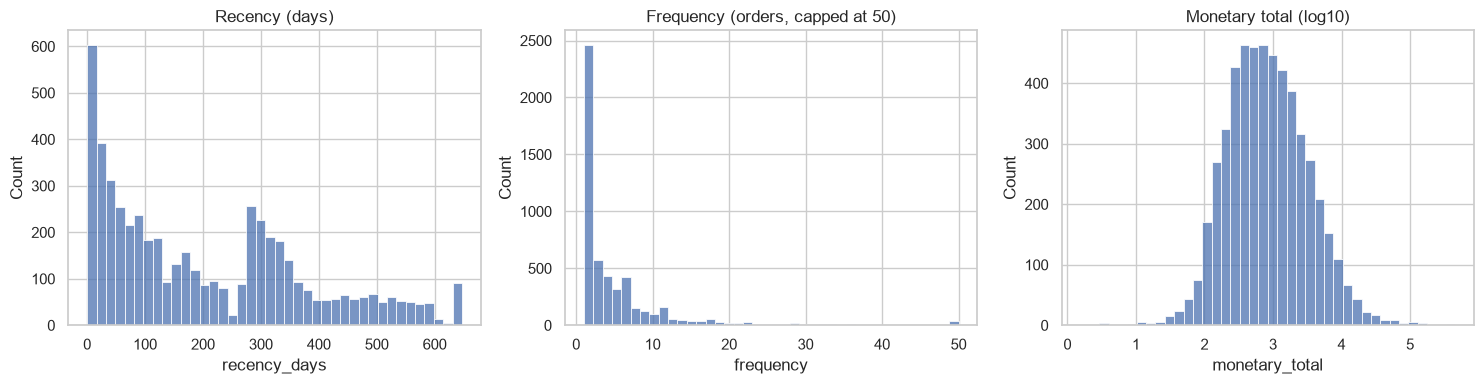

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(cust["recency_days"], bins=40, ax=axes[0]).set_title("Recency (days)")
sns.histplot(cust["frequency"].clip(upper=50), bins=40, ax=axes[1]).set_title("Frequency (orders, capped at 50)")
sns.histplot(np.log10(cust["monetary_total"].clip(lower=1)), bins=40, ax=axes[2]).set_title("Monetary total (log10)")
plt.tight_layout()
plt.show()

### Churn rate by recency bucket

The pipeline run on the real data gave a churn rate of about 56.5%. This table shows where that churn comes from. If most churn sits in customers who last bought more than 180 days before the cutoff, the label is dominated by long-lapsed customers, and we should consider restricting the modeling table to recently active customers.

In [9]:
bins = [-1, 30, 90, 180, 365, 10_000]
labels = ["0-30 days", "31-90 days", "91-180 days", "181-365 days", "over 365 days"]
bucket = pd.cut(cust["recency_days"], bins=bins, labels=labels)
summary = cust.groupby(bucket, observed=True).agg(customers=("customer_id", "count"), churn_rate=("churn_90d", "mean"))
summary["share_of_customers"] = (summary["customers"] / len(cust)).round(3)
summary["churn_rate"] = summary["churn_rate"].round(3)
summary

,customers,churn_rate,share_of_customers
recency_days,,,
0-30 days,956,0.247,0.182
31-90 days,947,0.374,0.180
91-180 days,882,0.539,0.168
181-365 days,1530,0.695,0.291
over 365 days,941,0.894,0.179


Customers with recency above 180 days are 47% of all customers (2,471 of 5,256) and have a churn rate of about 77%. They make up about 64% of all churners. Customers who bought in the last 180 days (2,785) have a churn rate of about 38%. Churn rises steadily with recency (25% to 89%), but recency alone does not decide it: even among customers who bought in the last 30 days, 24.7% did not return, and 10.6% of customers silent for more than a year bought again in the label window. Decision: keep all customers (Option A, closest to the PRD label) and report model metrics for all customers and for recently active customers (recency up to 180 days) as a robustness check.

## 4. Features versus churn (bivariate)

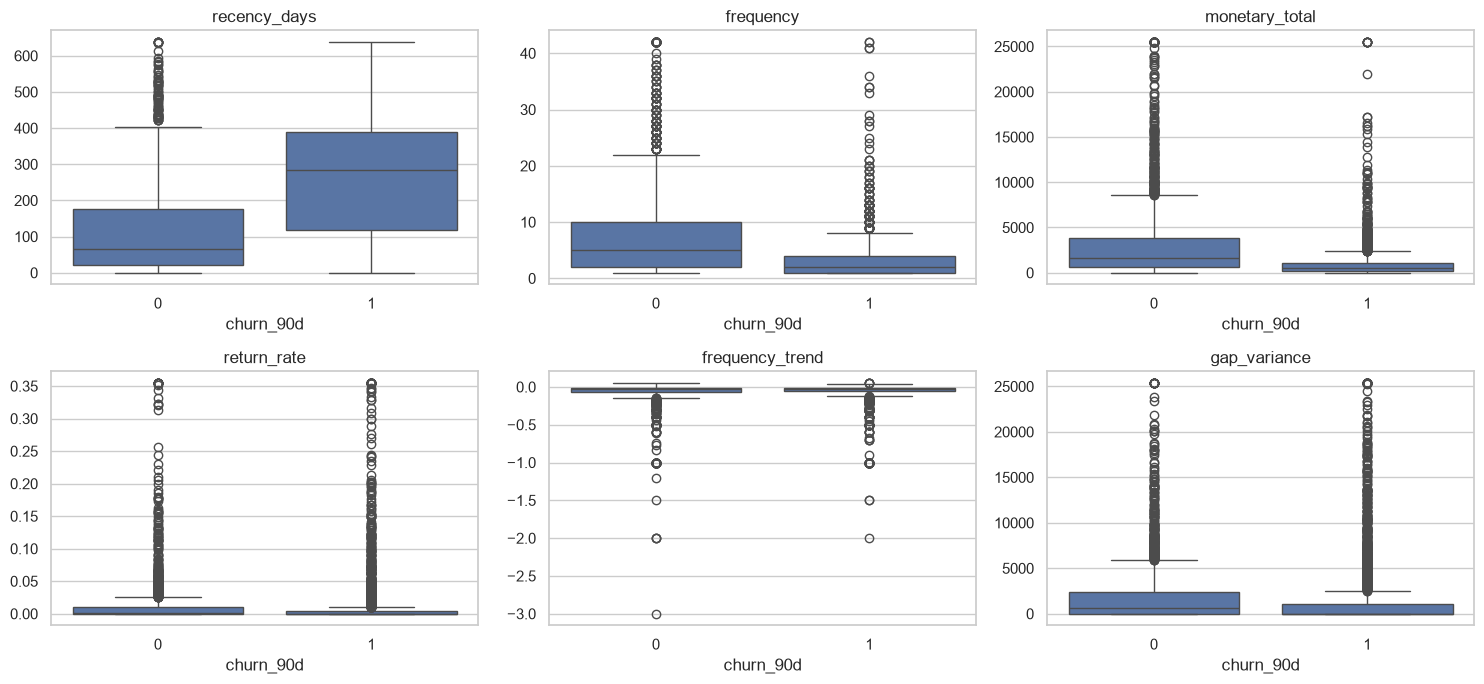

,recency_days,frequency,monetary_total,return_rate,frequency_trend,gap_variance
churn_90d,,,,,,
0,66.0,5.0,1583.47,0.0,-0.03,636.8
1,285.0,2.0,475.86,0.0,-0.03,0.0


In [10]:
cols = ["recency_days", "frequency", "monetary_total", "return_rate", "frequency_trend", "gap_variance"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, col in zip(axes.ravel(), cols):
    upper = cust[col].quantile(0.99)
    sns.boxplot(
        data=cust.assign(v=cust[col].clip(upper=upper)),
        x="churn_90d",
        y="v",
        ax=ax
    )
    ax.set_title(col)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

cust.groupby("churn_90d")[cols].median().round(2)

## 5. Correlation analysis and multicollinearity (VIF)

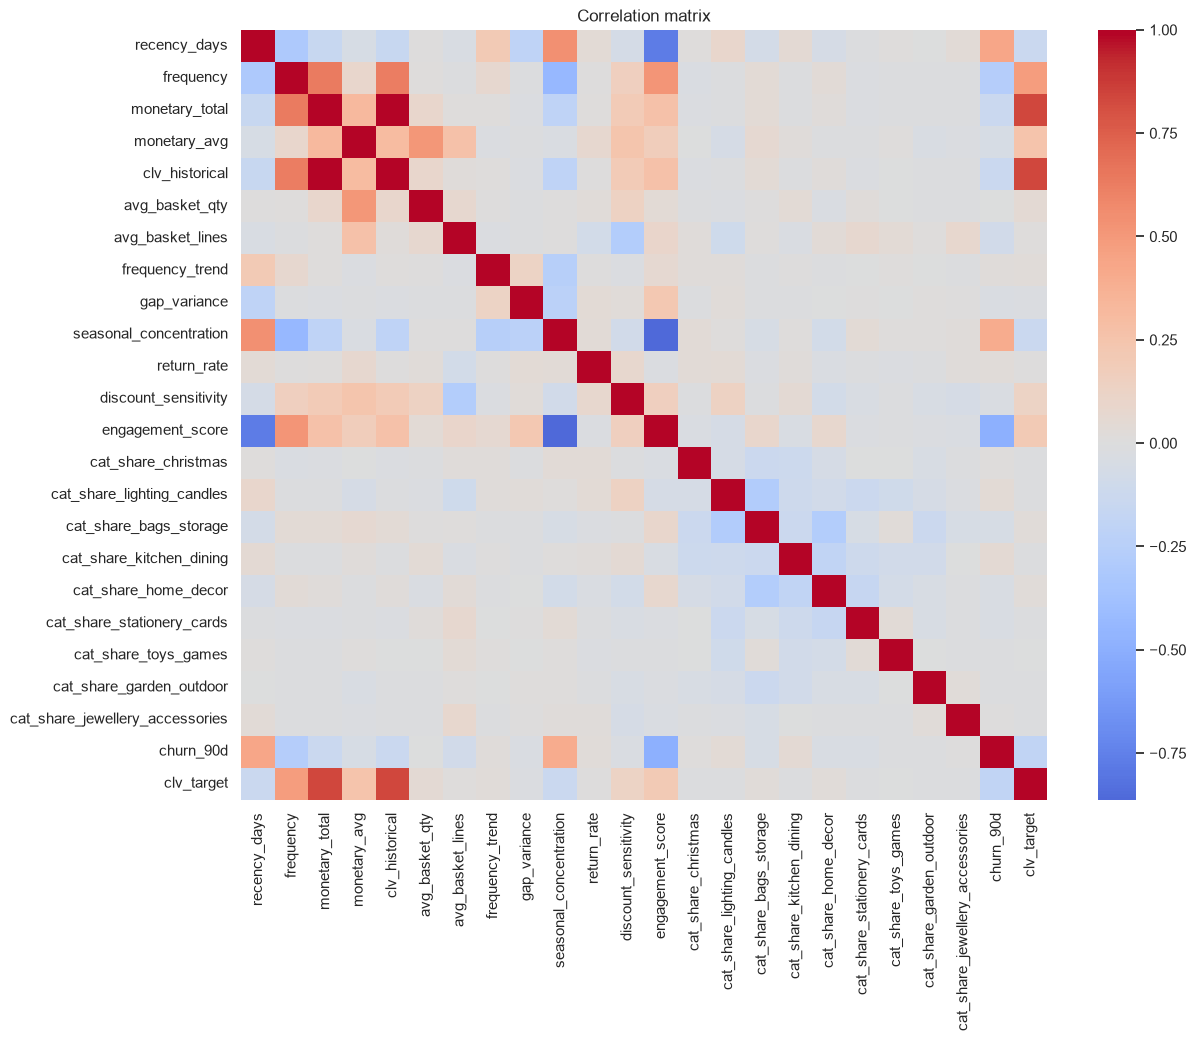

,churn_90d,clv_target
engagement_score,-0.494,0.204
frequency,-0.271,0.477
clv_historical,-0.142,0.836
monetary_total,-0.142,0.835
avg_basket_lines,-0.088,0.012
monetary_avg,-0.053,0.253
cat_share_bags_storage,-0.050,0.029
cat_share_home_decor,-0.038,0.029
cat_share_stationery_cards,-0.034,-0.014
gap_variance,-0.032,-0.024


In [11]:
corr = cust[FEATURES + TARGET_COLUMNS].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix")
plt.show()
target_correlations(cust, FEATURES, TARGET_COLUMNS).round(3).sort_values("churn_90d")

In [12]:
# VIF above about 10 signals multicollinearity. Constant columns are dropped first.
usable = [c for c in FEATURES if cust[c].nunique() > 1]
vif_table(cust, usable).round(2)

,feature,vif
0,monetary_total,620.35
1,clv_historical,604.56
2,engagement_score,12.22
3,seasonal_concentration,6.02
4,recency_days,3.79
5,frequency,2.53
6,monetary_avg,2.19
7,cat_share_bags_storage,1.58
8,cat_share_home_decor,1.46
9,cat_share_lighting_candles,1.41


## 6. Hypotheses for the modeling stage

These are expectations to be **tested**, not findings. Check each one against the plots and tables above, then confirm or reject it in Week 2.

1. **Recency** is the strongest single predictor of churn: customers who bought recently are less likely to churn.
2. **Frequency** and **monetary value** are negatively associated with churn (loyal, high-spending customers churn less).
3. **Return rate** is positively associated with churn.
4. A **negative frequency trend** (orders per month decreasing) is associated with higher churn.
5. The label window covers the Oct-Dec holiday season, yet the observed churn rate is high (about 56.5% on the real data). Part of it is probably customers who stopped buying long before the cutoff (see the recency-bucket table above).
6. `monetary_total`, `clv_historical` and `engagement_score` will be highly **collinear** (VIF above 10). Drop or combine them for Logistic Regression. (Category shares sum to 1, so the pipeline leaves out the `other` share as the reference category.)
7. Churn is **not a rare class** (about 56.5% churn against 43.5% retained), so SMOTE is probably unnecessary; use recall, F1 and ROC-AUC anyway, because the PRD targets churned-class recall of at least 0.70.

*After running the notebook, write below which hypotheses were supported and which were not.*

- H1 supported: recency has a correlation of +0.43 with churn, and the median recency is 66 days for retained customers versus 285 for churned ones.
- H2 supported for frequency (correlation -0.27, median 5 versus 2 orders). Weaker for total spend (correlation -0.14).
- H3 not supported: return rate has almost no relation with churn (correlation 0.03, median 0 in both groups).
- H4 not supported: frequency trend is almost unrelated to churn (correlation 0.02).
- H5 partly supported: the label window includes the holiday season and 10.6% of customers silent for over a year bought again in it, which is possibly seasonal returners. Churn is still high (56.5%).
- H6 supported: monetary_total (VIF 620) and clv_historical (VIF 605) are almost duplicates, and engagement_score (VIF 12) is built from other features. I will drop clv_historical and engagement_score for linear models. The category shares were perfectly collinear until I removed the "other" share.
- H7 supported: churn is 56.5%, so it is not a rare class and SMOTE is probably not needed.